#  Convolutional NN.  Learns for the smaller patterns rather than global pattern.  (Eg. three horizontal lines)

![alt text](localpattern.png "local pattern")


In [4]:
import tensorflow as tf
#tf.__version__
import matplotlib.pyplot as plt
import numpy as np



In [5]:
mnist = tf.keras.datasets.mnist  # hand written digits, 28 X 28 images

In [6]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
printable_train_images = train_images
printable_test_images = test_images

print(train_images.shape)


(60000, 28, 28)


In [9]:
print(train_images[50])  #kinda looks like a 3


[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  12  56 140 126 175 200  96   2
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  35 166 238 254 246 242 253 246 254  67
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 184 182 146 127  70  30  45  36 215 175
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30   0   0   0   0   0   0   0 207 246
   14   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  5

In [10]:


train_images = train_images.reshape((60000,28,28,1))  # change format so each image is unrolled into an array of 1-D arrays 
print(train_images.shape) # 60000 images, 28 X, 28 Y, 1 color


(60000, 28, 28, 1)


In [11]:
#print(train_images[50])  # take a look at the format

## normalize to a value between 0 and 1

In [12]:
train_images = train_images.astype('float32')/255  #another way of normalizing

In [13]:
#print(train_images[50])  # another sanity check

In [14]:
test_images = test_images.reshape(10000,28,28,1)
test_images = test_images.astype('float32')/255 

## One Hot encode

In [15]:
train_labels = tf.keras.utils.to_categorical(train_labels)
test_labels = tf.keras.utils.to_categorical(test_labels)

## Model

In [22]:
model = tf.keras.models.Sequential() # one input and one output

### Add a convolutional layer with 32 filters each is 3X3
![alt text](convlayer.png "convolutional layer 32 filters of 3X3")
### Note that you "lose" some pixels due to the border overlap.   You can manually the shape of the output be the same (28,28,1)

In [23]:
model.add(tf.keras.layers.Conv2D( 32, (3,3) , activation='relu', input_shape = (28,28,1)))  # see https://keras.io/api/layers/convolution_layers/convolution2d/
          

### Apply Max pooling, poolsize = 2X2, stride = also 2X2 as it will default to pool_sizer if strides is omitted
![alt text](cnnDesign.png "CNN Design")

In [24]:

model.add(tf.keras.layers.MaxPooling2D( pool_size=(2,2), strides=(2,2))) # see https://keras.io/api/layers/pooling_layers/max_pooling2d/

In [25]:
model.add(tf.keras.layers.Conv2D( 64, (3,3) , activation='relu' ))

In [26]:
model.add(tf.keras.layers.MaxPooling2D( pool_size=(2,2), strides=(2,2))) # see https://keras.io/api/layers/pooling_layers/max_pooling2d/

In [27]:
model.add(tf.keras.layers.Conv2D( 64, (3,3) , activation='relu' ))

In [28]:
model.add(tf.keras.layers.Flatten()) # unwrapp rows into one single row.

## Add Fully connected layer:

In [29]:
model.add(tf.keras.layers.Dense(64, activation = 'relu'))   #hidden layer

In [30]:
model.add(tf.keras.layers.Dense(10, activation= 'softmax')) #output layer 0 to 9

In [31]:
model.summary() #sanity check

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 32)       0         
 )                                                               
                                                                 
 conv2d_6 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 64)         0         
 2D)                                                             
                                                                 
 conv2d_7 (Conv2D)           (None, 3, 3, 64)          36928     
                                                                 
 flatten (Flatten)           (None, 576)              

In [32]:
##### SIMPLEr MODEL FOR VISUALIZATION

#model = tf.keras.models.Sequential([
#    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', input_shape=(28, 28, 1)),  # 16 filters in the first Conv layer
#    tf.keras.layers.MaxPooling2D((2, 2)),  # MaxPooling layer to reduce dimensions
#    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),  # 32 filters in the second Conv layer
#    tf.keras.layers.MaxPooling2D((2, 2)),  # Another MaxPooling layer
#    tf.keras.layers.Flatten(),  # Flatten the feature maps
#    tf.keras.layers.Dense(10, activation='softmax')  # Dense layer for 10-class classification (MNIST)
#])




## Train

In [34]:
model.compile (optimizer = 'rmsprop', loss = 'categorical_crossentropy', metrics = ['accuracy'] )
history = model.fit(train_images, train_labels, epochs=10, batch_size=2500, validation_data=(test_images, test_labels))



Epoch 1/10


2024-10-23 13:19:07.142797: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8101


24/24 [==============================] - 17s 35ms/step - loss: 1.3086 - accuracy: 0.6148 - val_loss: 0.7407 - val_accuracy: 0.7799
Epoch 2/10
24/24 [==============================] - 1s 25ms/step - loss: 0.4714 - accuracy: 0.8604 - val_loss: 0.2774 - val_accuracy: 0.9219
Epoch 3/10
24/24 [==============================] - 1s 25ms/step - loss: 0.3014 - accuracy: 0.9099 - val_loss: 0.1915 - val_accuracy: 0.9474
Epoch 4/10
24/24 [==============================] - 1s 25ms/step - loss: 0.2351 - accuracy: 0.9280 - val_loss: 0.1622 - val_accuracy: 0.9551
Epoch 5/10
24/24 [==============================] - 1s 25ms/step - loss: 0.1746 - accuracy: 0.9466 - val_loss: 0.1100 - val_accuracy: 0.9689
Epoch 6/10
24/24 [==============================] - 1s 25ms/step - loss: 0.1328 - accuracy: 0.9598 - val_loss: 0.1055 - val_accuracy: 0.9664
Epoch 7/10
24/24 [==============================] - 1s 25ms/step - loss: 0.1123 - accuracy: 0.9651 - val_loss: 0.1683 - val_accuracy: 0.9517
Epoch 8/10
24/24 [=====

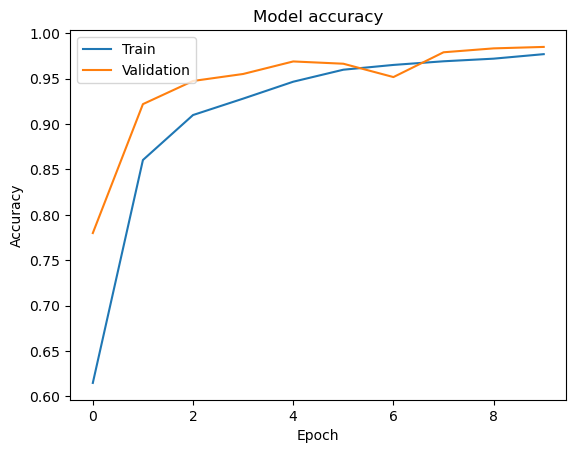

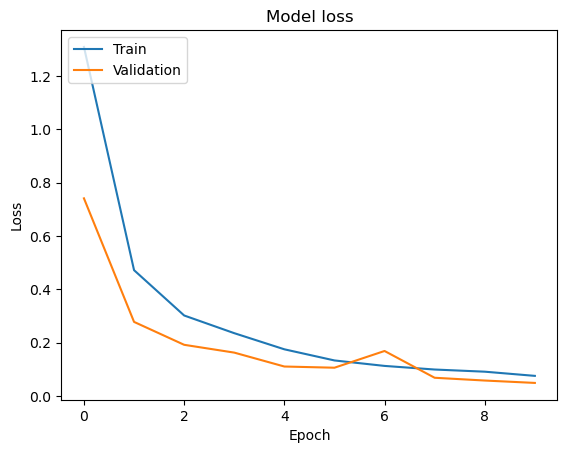

In [35]:


# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()


In [36]:
model.evaluate(test_images,test_labels)

313/313 [==============================] - 1s 2ms/step - loss: 0.0485 - accuracy: 0.9849


[0.04850209504365921, 0.9848999977111816]

In [41]:
model.save('mycnnmodel.model')  # a file should appear

INFO:tensorflow:Assets written to: mycnnmodel.model/assets


INFO:tensorflow:Assets written to: mycnnmodel.model/assets


In [42]:
modelReadIn = tf.keras.models.load_model('mycnnmodel.model')

In [43]:
predictions = modelReadIn.predict([test_images])

313/313 [==============================] - 1s 2ms/step


0


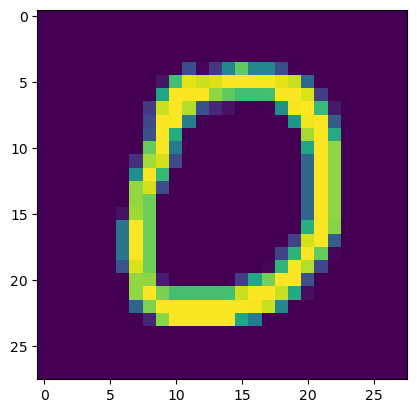

In [46]:
print( np.argmax(predictions[10]))   # just pick some random images
plt.imshow(printable_test_images[10])

In [47]:
model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 32)       0         
 )                                                               
                                                                 
 conv2d_6 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 64)         0         
 2D)                                                             
                                                                 
 conv2d_7 (Conv2D)           (None, 3, 3, 64)          36928     
                                                                 
 flatten (Flatten)           (None, 576)              

# Visualizing filters
## model has an array of matrices. The convolutional layers are at index 0, 2, 4

In [246]:
all_layers = model.layers

In [247]:
print ( all_layers ) #meh not helpful

[<keras.layers.convolutional.conv2d.Conv2D object at 0x7f62e9d93a90>, <keras.layers.pooling.max_pooling2d.MaxPooling2D object at 0x7f62e7df5810>, <keras.layers.convolutional.conv2d.Conv2D object at 0x7f62e9bc3f70>, <keras.layers.pooling.max_pooling2d.MaxPooling2D object at 0x7f62e7df5c90>, <keras.layers.convolutional.conv2d.Conv2D object at 0x7f62e7df4880>, <keras.layers.reshaping.flatten.Flatten object at 0x7f62e9bc3ee0>, <keras.layers.core.dense.Dense object at 0x7f62e9bc2da0>, <keras.layers.core.dense.Dense object at 0x7f62e9bc3010>]


In [248]:
print ( all_layers[0] ) #verify layer 0 in a Conv2d

In [249]:
print ( all_layers[1] ) # note that layer 1 is a maxPool, etc.

In [250]:
 filters, biases = all_layers[0].get_weights()  #filters is all of the filters/weights in the first conv layer 

In [252]:
#print (filters )


In [253]:
print (all_layers[0].name, filters.shape)  # first layer has 3 X 3 X 1 X 32,    rows and cols are 3,  1 is for monochrome (as opposed to RGB),  and 32 filters 

conv2d_21 (3, 3, 1, 32)


<Figure size 800x1200 with 0 Axes>

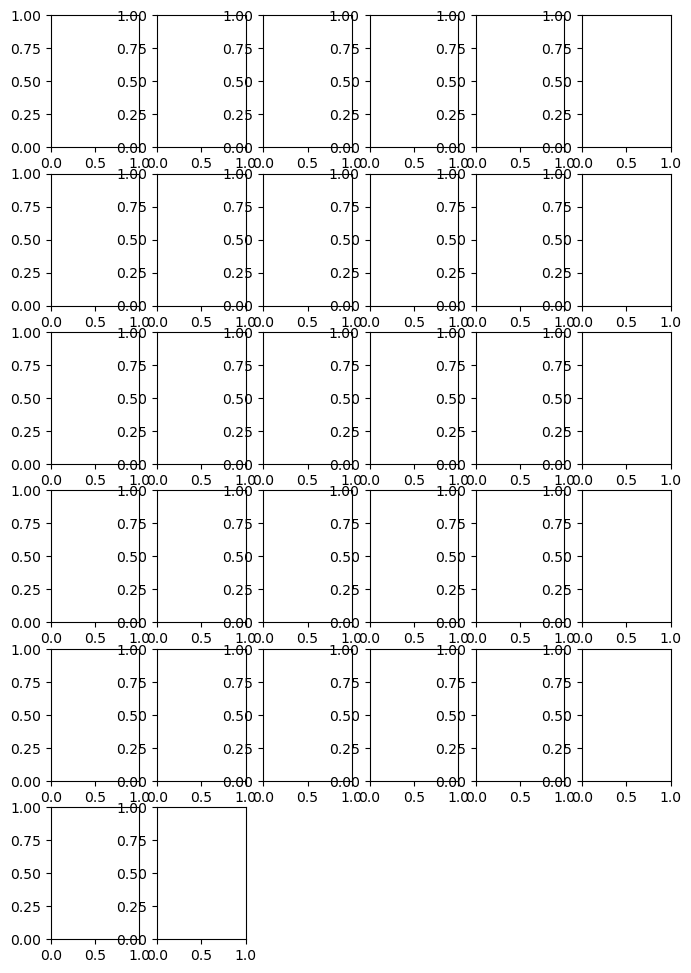

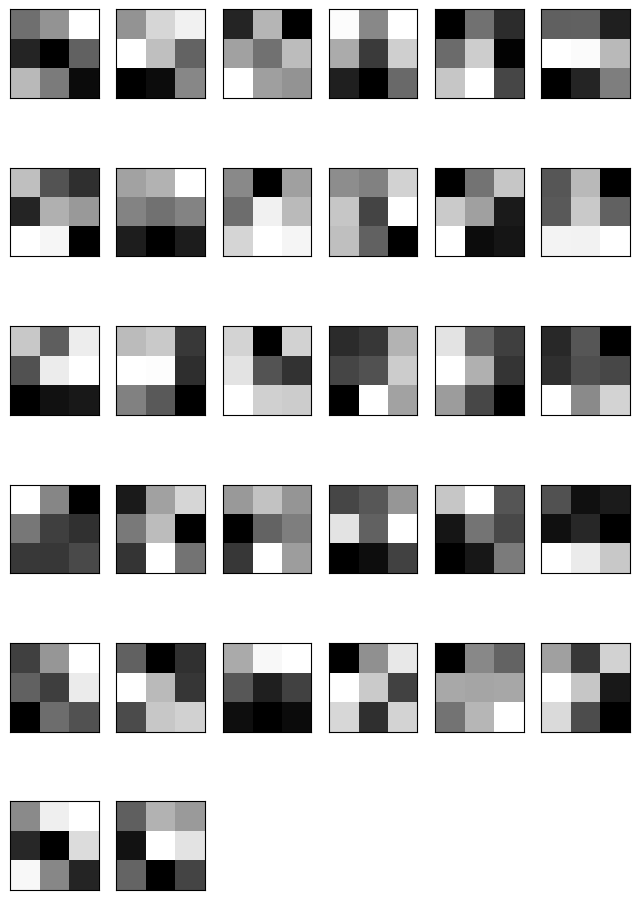

In [260]:
# FIRST CONVOLUTIONAL LAYER:  look for features
# Likely will have edges ( horizaontal, vertical, diagonal):  Light on one side, dark on other side
#


# Create figure for subplots
figure1 = plt.figure(figsize=(8, 12))
columns = 6
rows = 6
n_filters = 32  # Number of filters in the layer (adjust as necessary)




# Loop over each filter and plot it
for i in range(1, n_filters + 1):
    f = filters[:, :, :, i - 1]  # Extract the i-th filter
    
    ax = plt.subplot(rows, columns, i)  # Add subplot in a grid
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    
    plt.imshow(f[:, :, 0], cmap='gray')  # Display the filter (assuming grayscale)

# Show the plot with all filters
plt.show()

# white is a high value in filter,  black is low

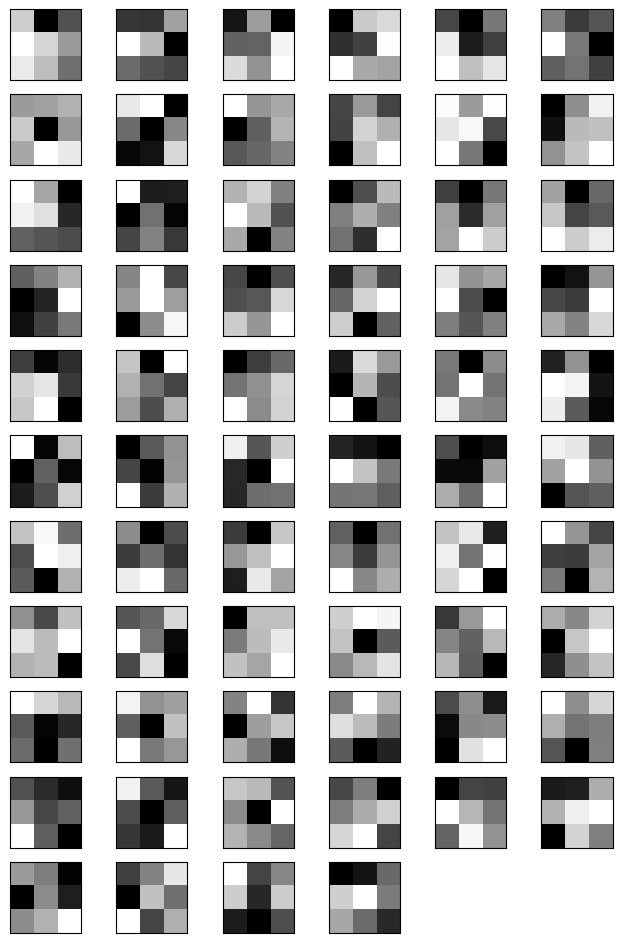

In [262]:
#Visualize second layer
#  (e.g., combining edges, textures, or shapes).
#Possible Features Detected by These Filters:
#Curved Shapes: Many of the filters likely detect curves or arcs, which could be parts of digits like "6", "9", or "8", where circular patterns are common.
#Diagonal or Intersection Points: Some filters could be focusing on intersections or diagonal lines, which are important for identifying digits like "4", "7", or "2".
#Textures and Partials: As the filters combine lower-level edges, they may start identifying partial shapes like the bottom loop of a "6" or the top of an "8".



filters, biases = model.layers[2].get_weights()

# Number of filters in the second convolutional layer
n_filters = filters.shape[3]  # Assuming this is correct for your layer

# Dynamically determine the number of rows and columns based on the number of filters
columns = 6
rows = (n_filters + columns - 1) // columns  # Ensures enough rows for all filters

# Create figure
figure2 = plt.figure(figsize=(8, 12))

# Loop to plot each filter
for i in range(1, n_filters + 1):
    f = filters[:, :, :, i - 1]  # Extract the i-th filter
    
    ax = plt.subplot(rows, columns, i)
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    
    plt.imshow(f[:, :, 0], cmap='gray')  # Display the filter

plt.show()


1/1 [==============================] - 0s 61ms/step


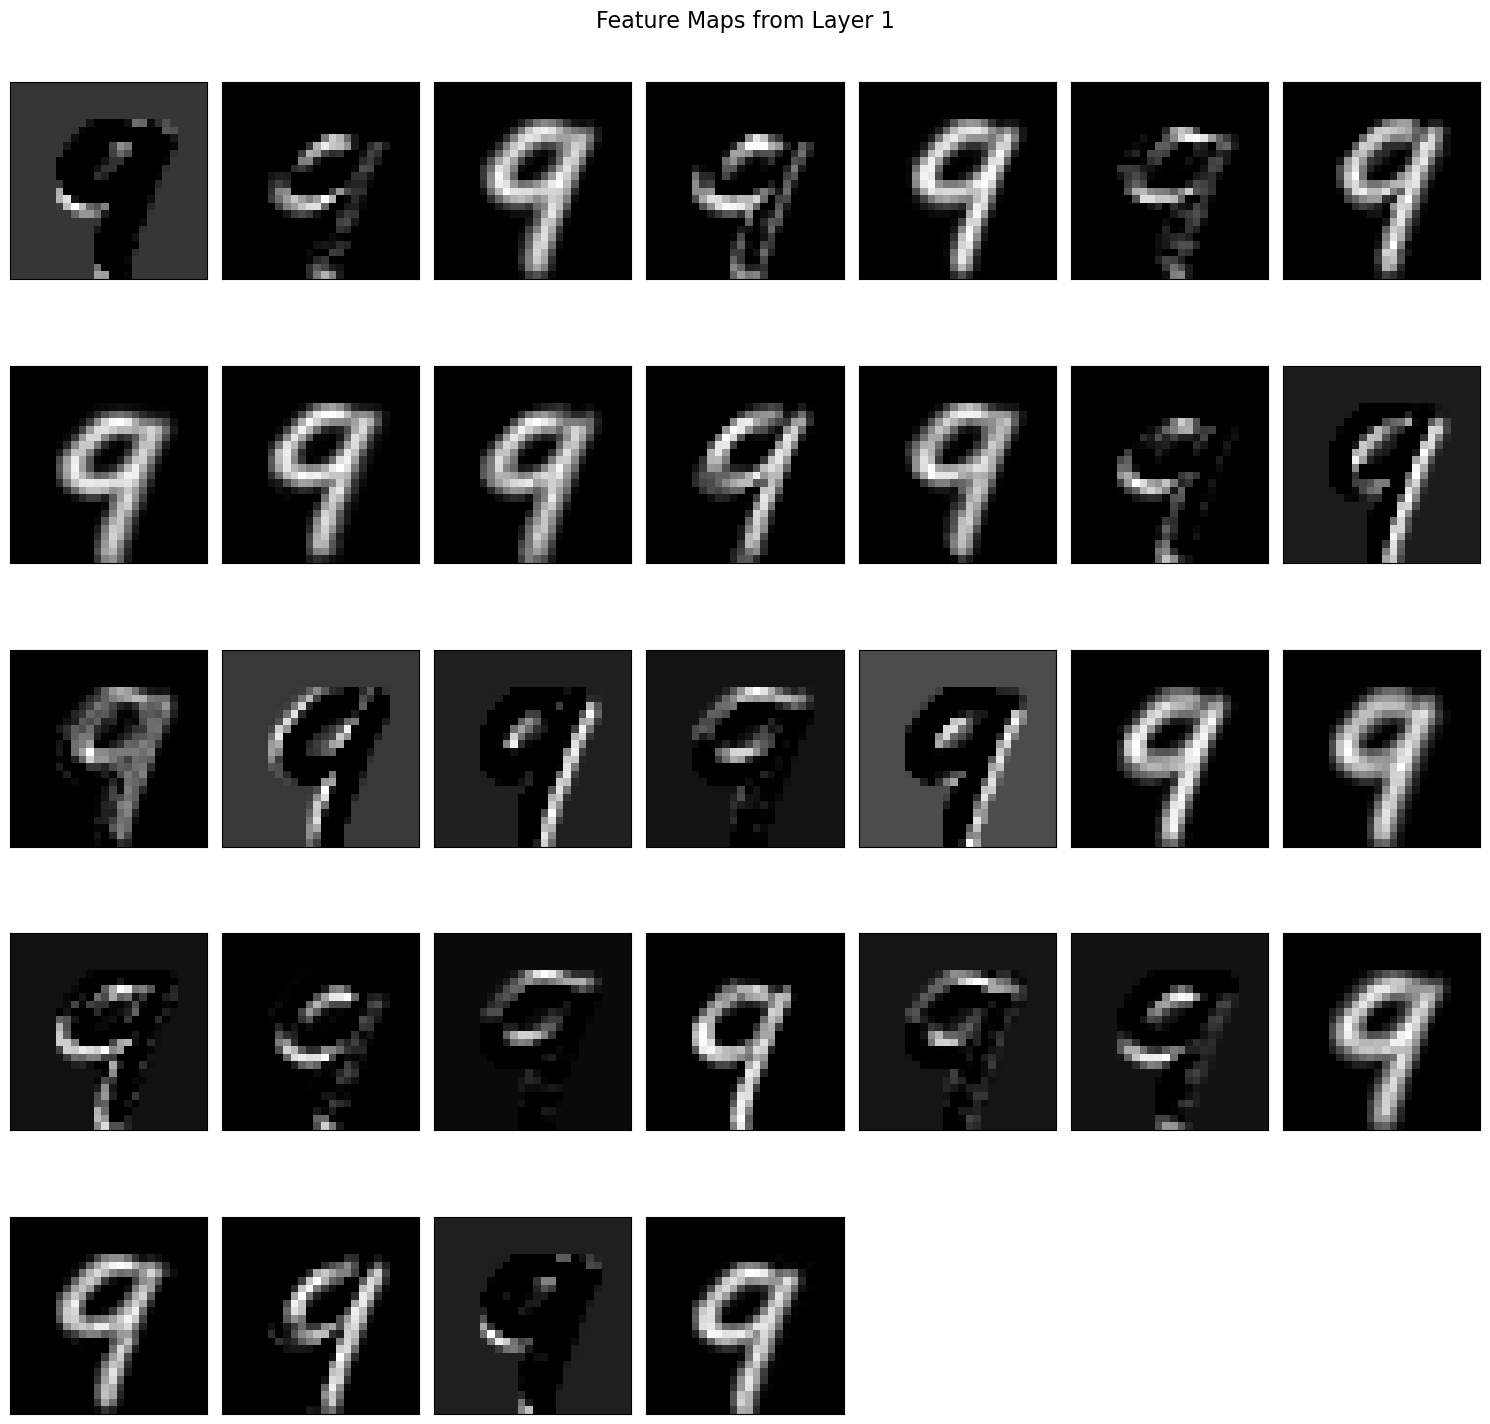

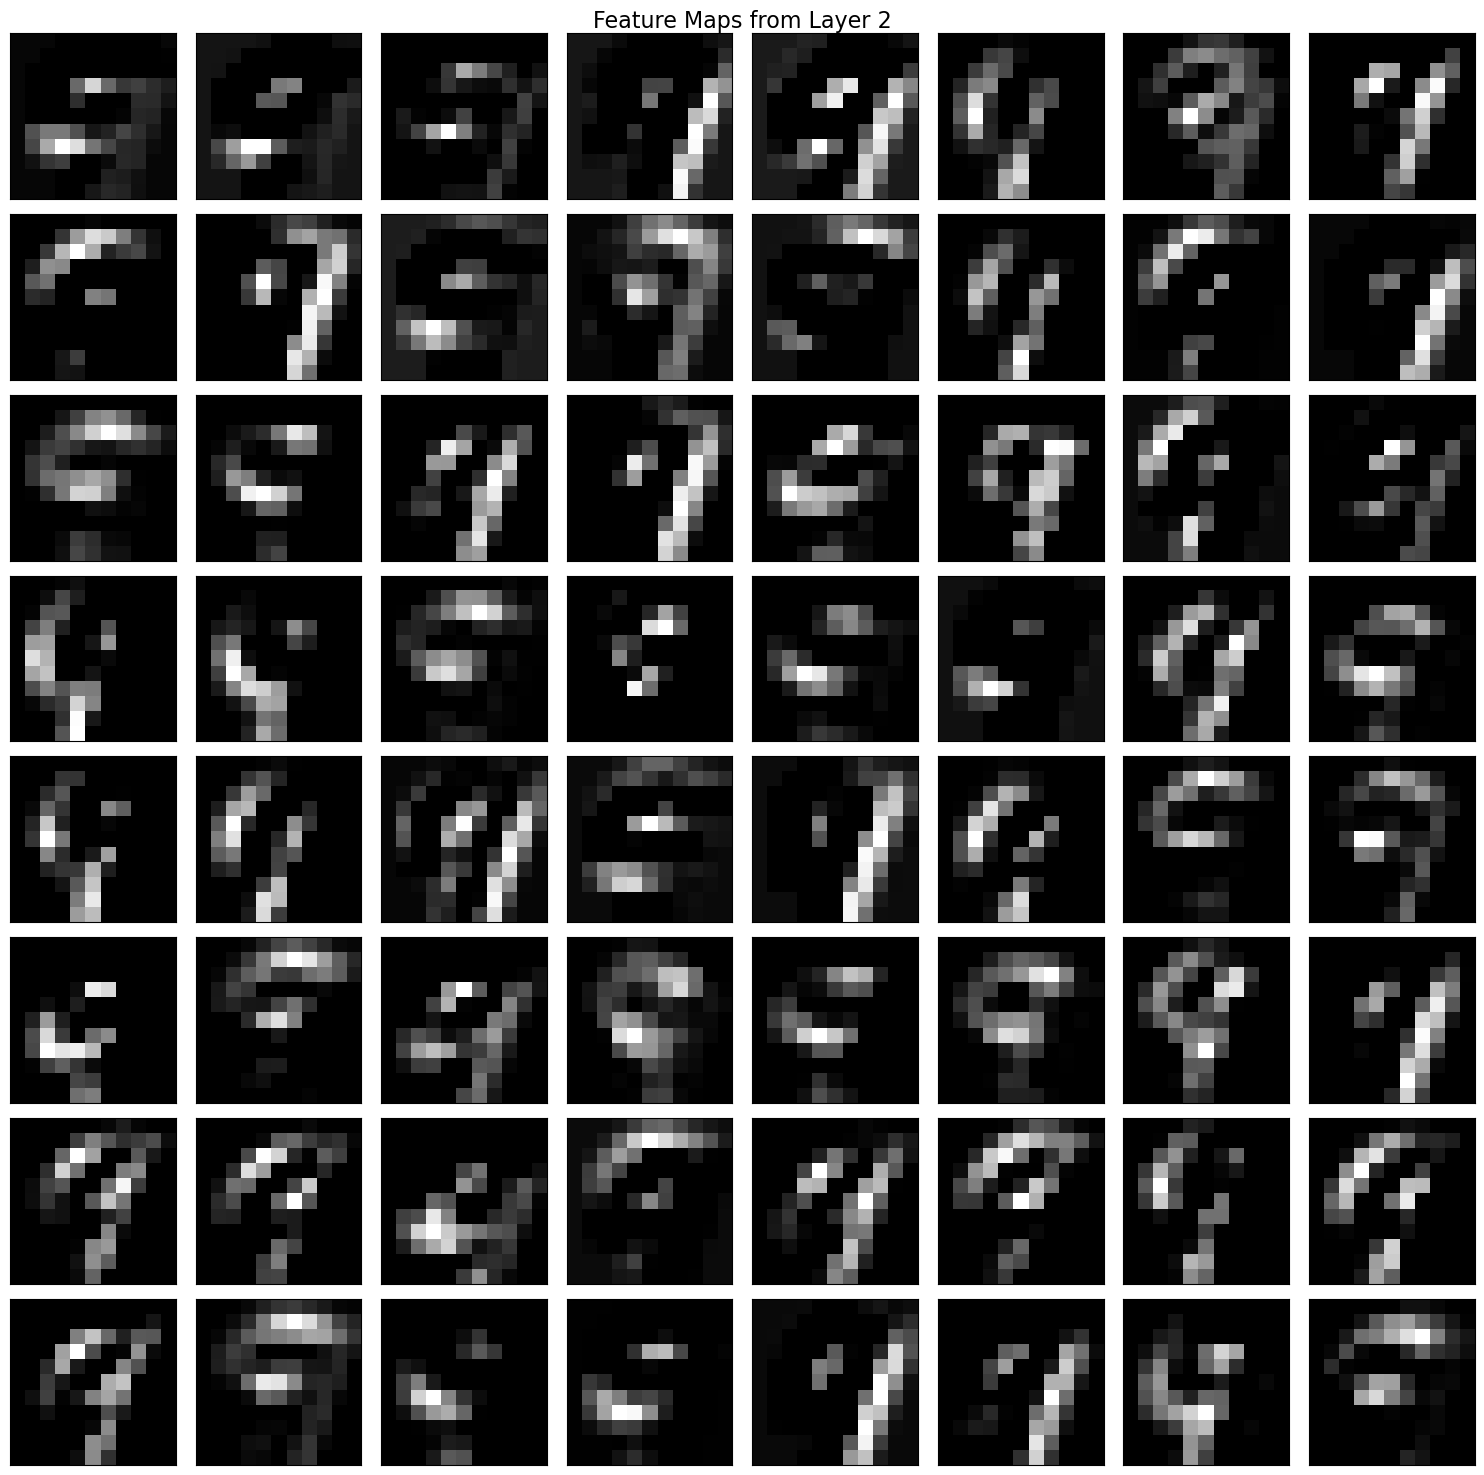

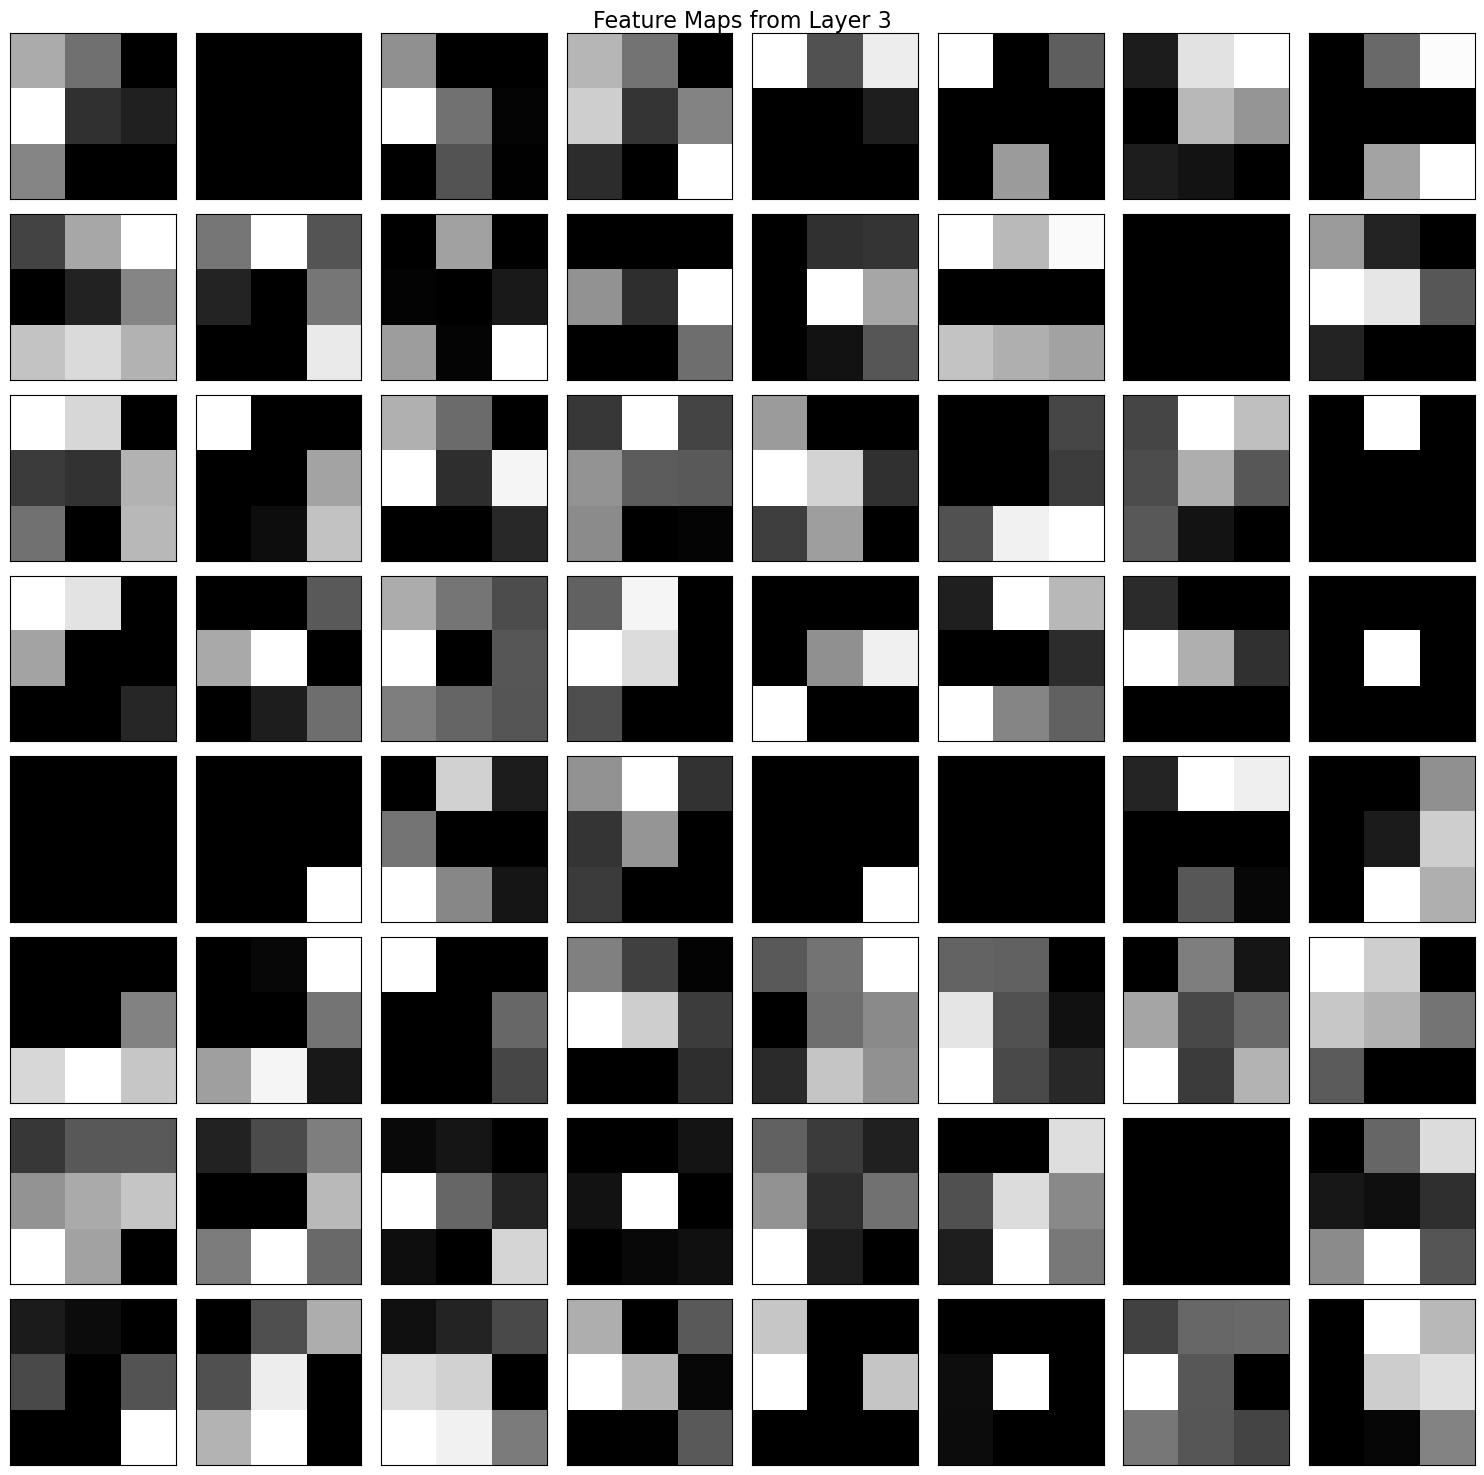

In [267]:
# visualization of numbers passed through first filter layer

# First layer will show basic features like edges and simple textures.  Some feture maps show the upper loop of a "9" and others show the contrast of edges

# Second layer will show more complex patterns:   Combinations of 



# Extract outputs of the convolutional layers only
layer_outputs = [layer.output for layer in model.layers if 'conv' in layer.name]
model_shortened = Model(inputs=model.input, outputs=layer_outputs)


testImageIndexToTry = 12
testImage = np.expand_dims(test_images[testImageIndexToTry], axis=0)

# Get feature maps for the test image
feature_maps = model_shortened.predict(testImage)

# Visualize the feature maps from each convolutional layer
for layer_index, feature_map in enumerate(feature_maps):
    num_filters = feature_map.shape[-1]
    
    # Dynamically determine the number of rows and columns for the subplots
    rows = int(np.sqrt(num_filters))  # Number of rows
    columns = int(np.ceil(num_filters / rows))  # Number of columns
    
    fig = plt.figure(figsize=(15, 15))
    fig.suptitle(f'Feature Maps from Layer {layer_index + 1}', fontsize=16)

    for i in range(1, num_filters + 1):
        plt.subplot(rows, columns, i)
        plt.xticks([])  # remove x-axis ticks
        plt.yticks([])  # remove y-axis ticks
        plt.imshow(feature_map[0, :, :, i - 1], cmap='gray')

    plt.tight_layout()  # Adjust subplots to fit in figure area.
    plt.show()

[<KerasTensor: shape=(None, 26, 26, 16) dtype=float32 (created by layer 'conv2d_14')>,
 <KerasTensor: shape=(None, 11, 11, 32) dtype=float32 (created by layer 'conv2d_15')>,
 <KerasTensor: shape=(None, 800) dtype=float32 (created by layer 'flatten_4')>]

Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_14_input (InputLayer  [(None, 28, 28, 1)]      0         
 )                                                               
                                                                 
 conv2d_14 (Conv2D)          (None, 26, 26, 16)        160       
                                                                 
 max_pooling2d_9 (MaxPooling  (None, 13, 13, 16)       0         
 2D)                                                             
                                                                 
 conv2d_15 (Conv2D)          (None, 11, 11, 32)        4640      
                                                                 
 max_pooling2d_10 (MaxPoolin  (None, 5, 5, 32)         0         
 g2D)                                                            
                                                           

1/1 [==============================] - 0s 65ms/step


IndexError: index 16 is out of bounds for axis 3 with size 16

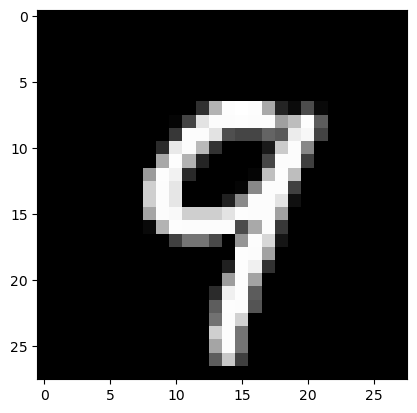

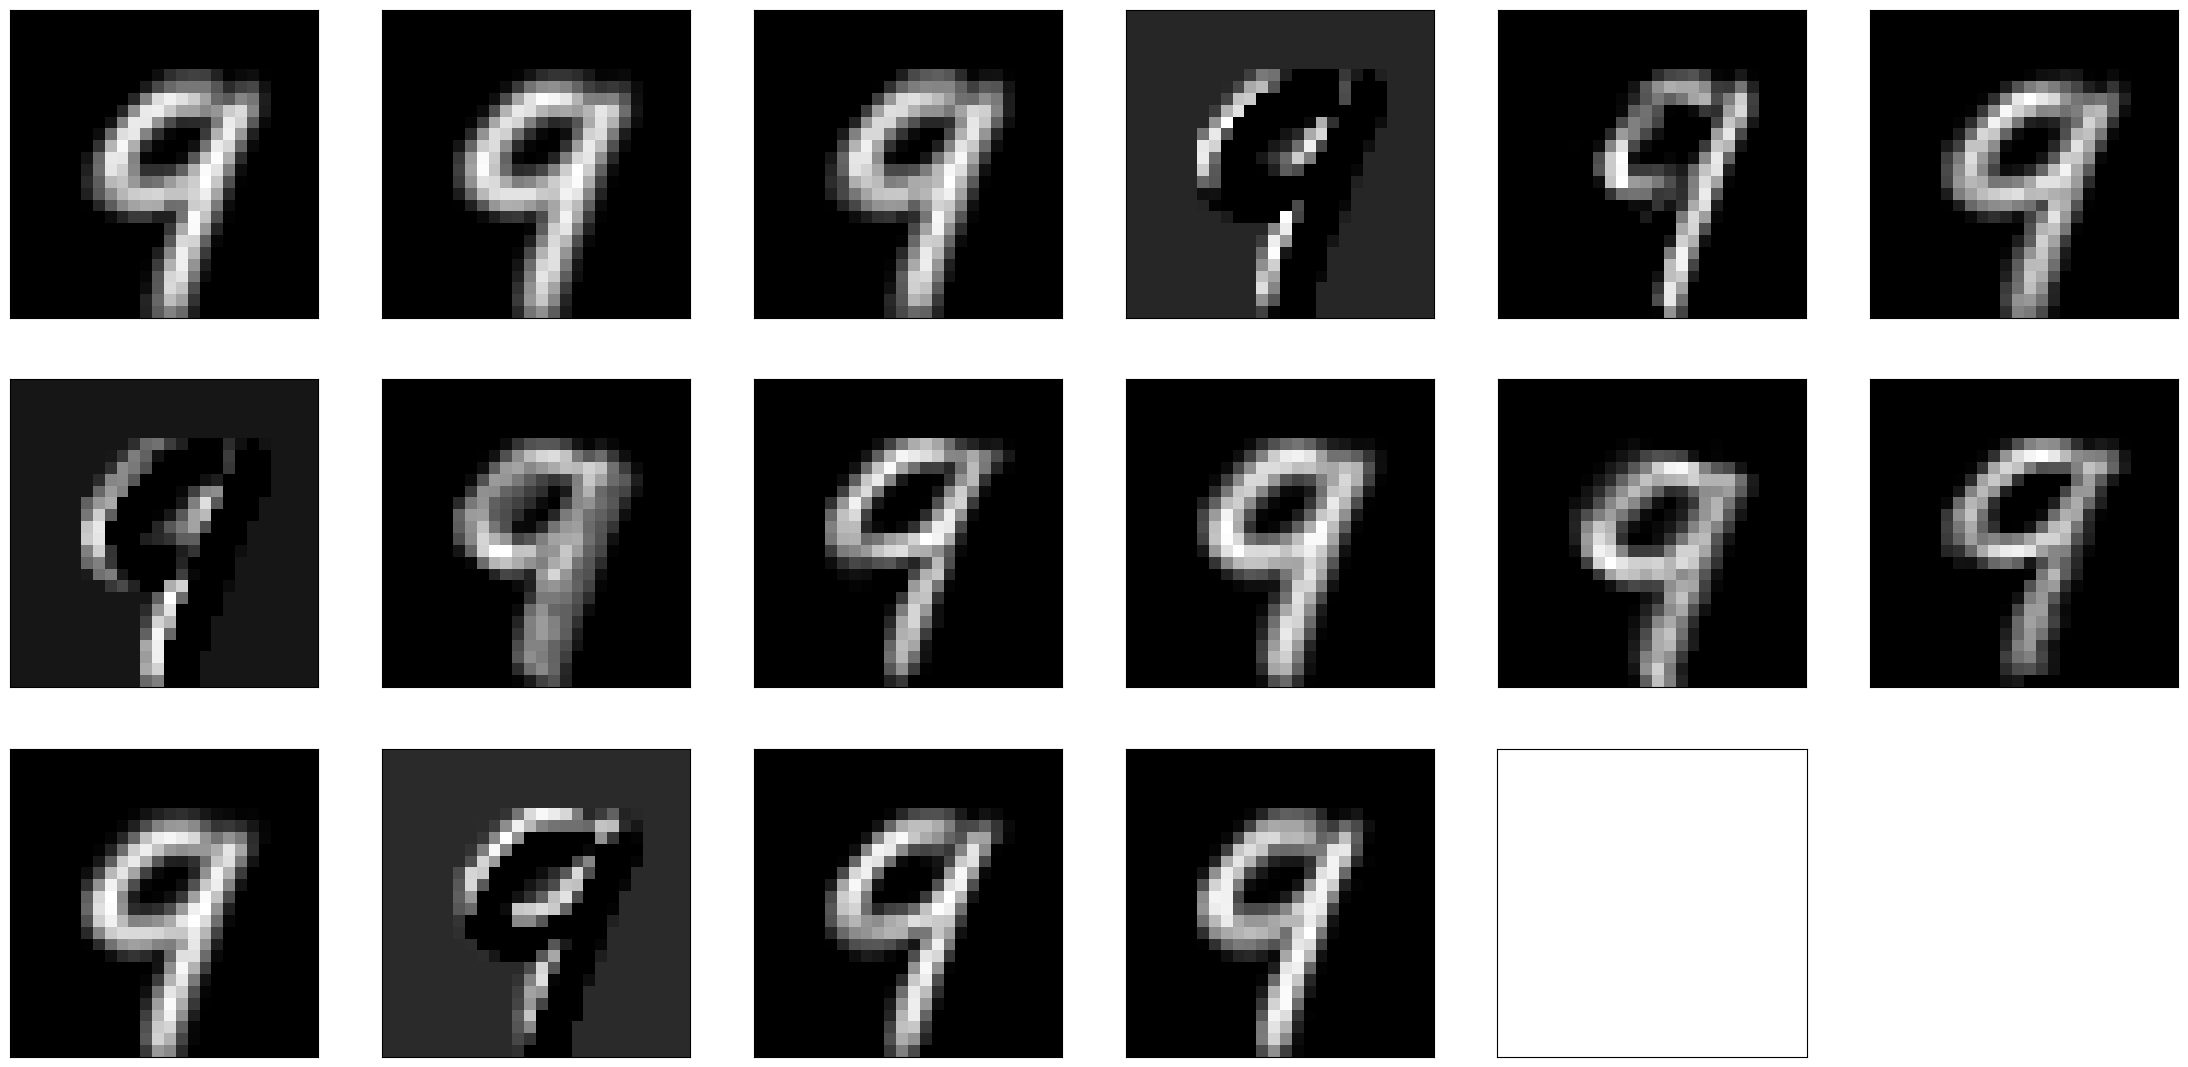

In [191]:
# put an image through the new model to see the output
columns = 6
rows = 6
testImageIndexToTry = 12
testImage = test_images[testImageIndexToTry]
testImage = np.expand_dims(testImage, axis=0)

plt.imshow(printable_test_images[testImageIndexToTry], cmap = 'gray')

feature_output = model_shortened.predict(testImage)
for the_filter in feature_output:
    figure2 = plt.figure(figsize=(28,28))
    for i in range ( 1, 32 + 1):
        figure2 = plt.subplot(rows,columns,i)
        figure2.set_xticks([]) 
        figure2.set_yticks([])
        plt.imshow(the_filter[0, :, :, i-1], cmap='gray') # cmap=binary,   or hot or gray , 
    plt.show()
    
    #note first filter  is detecting top and bottom edges
    
# example index numbers
# 0:  3,10,13
# 1:  2,5
# 2:  1, 
# 6:  11, 
# 4:  4,6 
# 9: 7,9,12

    
    # I cannot tell what index 8 is

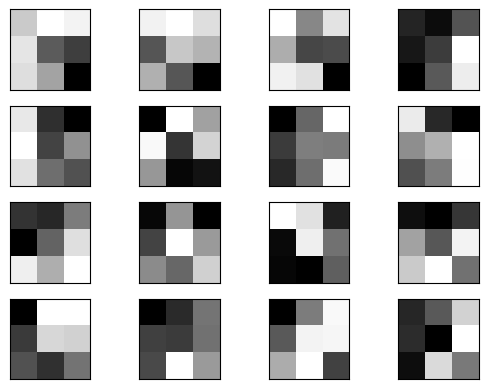

In [192]:
import numpy as np
import matplotlib.pyplot as plt

# Get filters and biases for the first conv layer
filters, biases = model.layers[0].get_weights()

# Normalize filter values to [0, 1] for better visualization
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

n_filters = filters.shape[3]
rows = 4  # Adjust according to the number of filters
columns = n_filters // rows

# Visualize the filters
for i in range(n_filters):
    f = filters[:, :, :, i]
    plt.subplot(rows, columns, i + 1)
    plt.xticks([])  # remove x-axis ticks
    plt.yticks([])  # remove y-axis ticks
    plt.imshow(f[:, :, 0], cmap='gray')  # Show the filter
plt.show()


In [193]:
from keras.models import Model

# Create a model that will return the outputs of the first 3 convolutional layers
layer_outputs = [layer.output for layer in model.layers[:5]]  # Get conv layers' outputs
model_shortened = Model(inputs=model.input, outputs=layer_outputs)


1/1 [==============================] - 0s 59ms/step


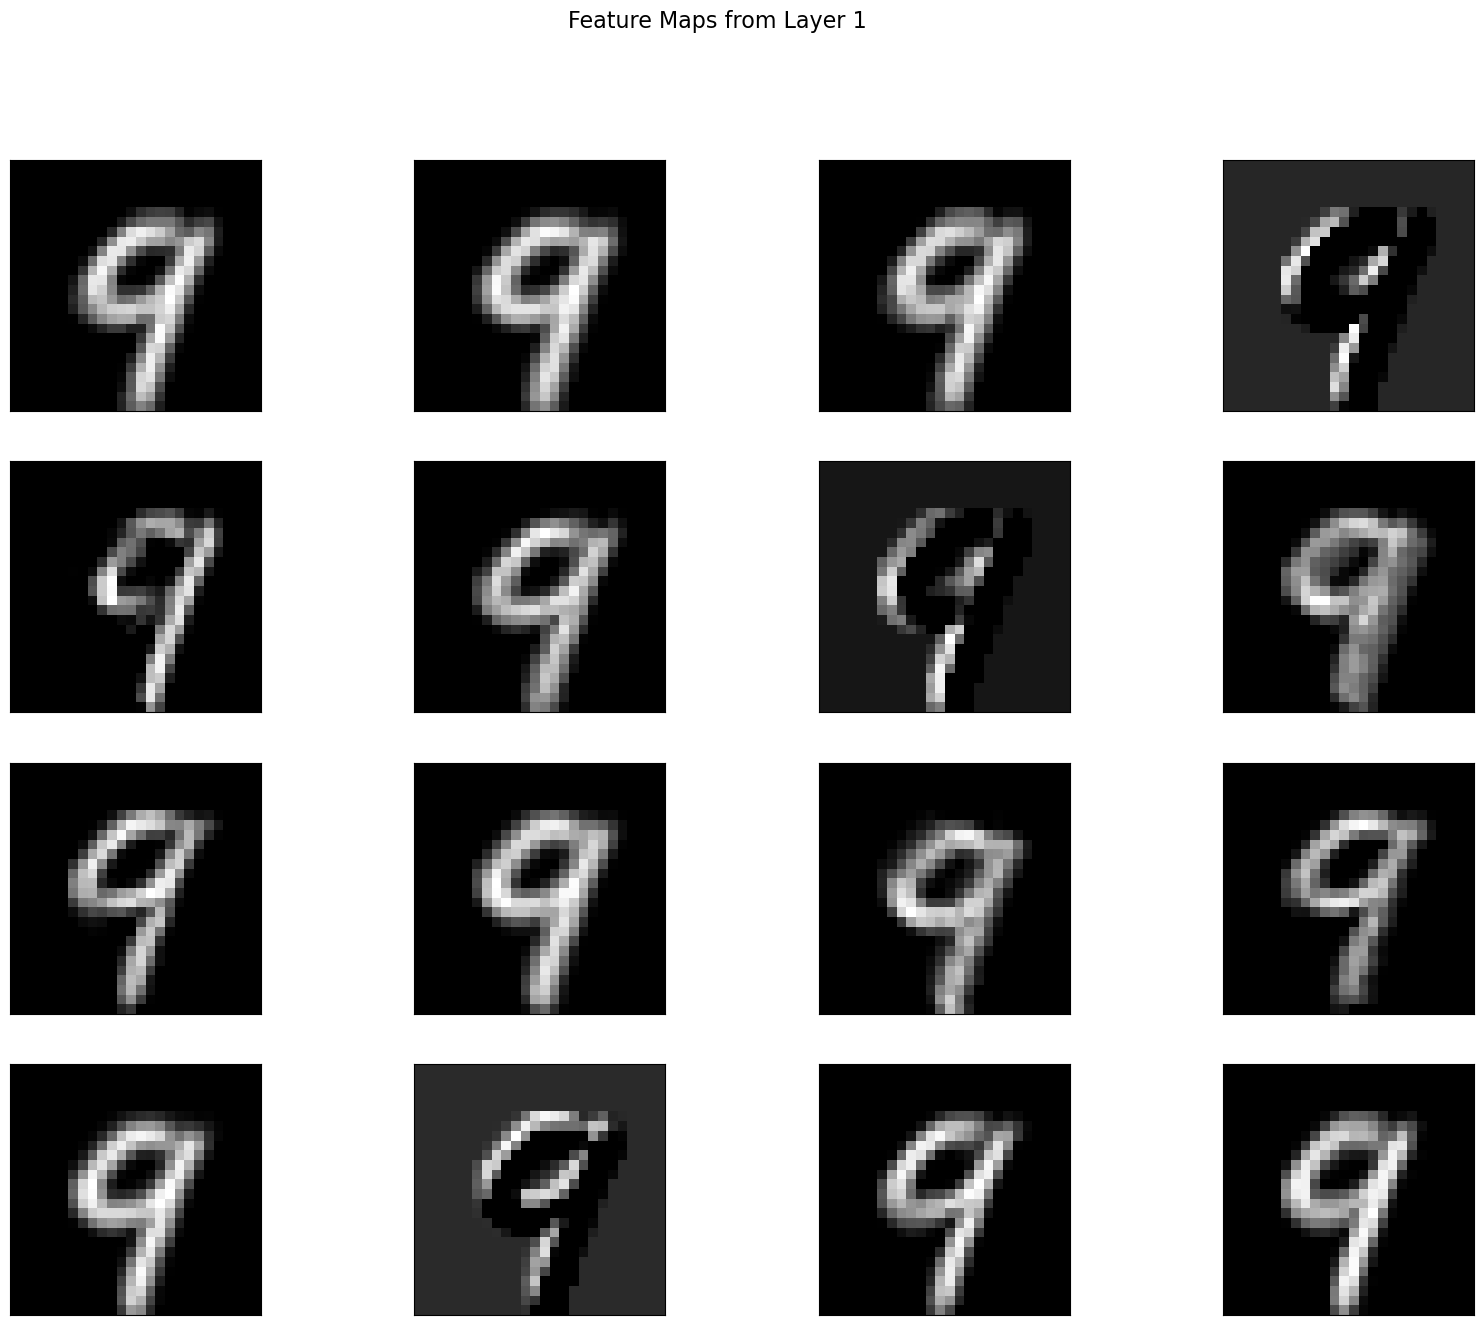

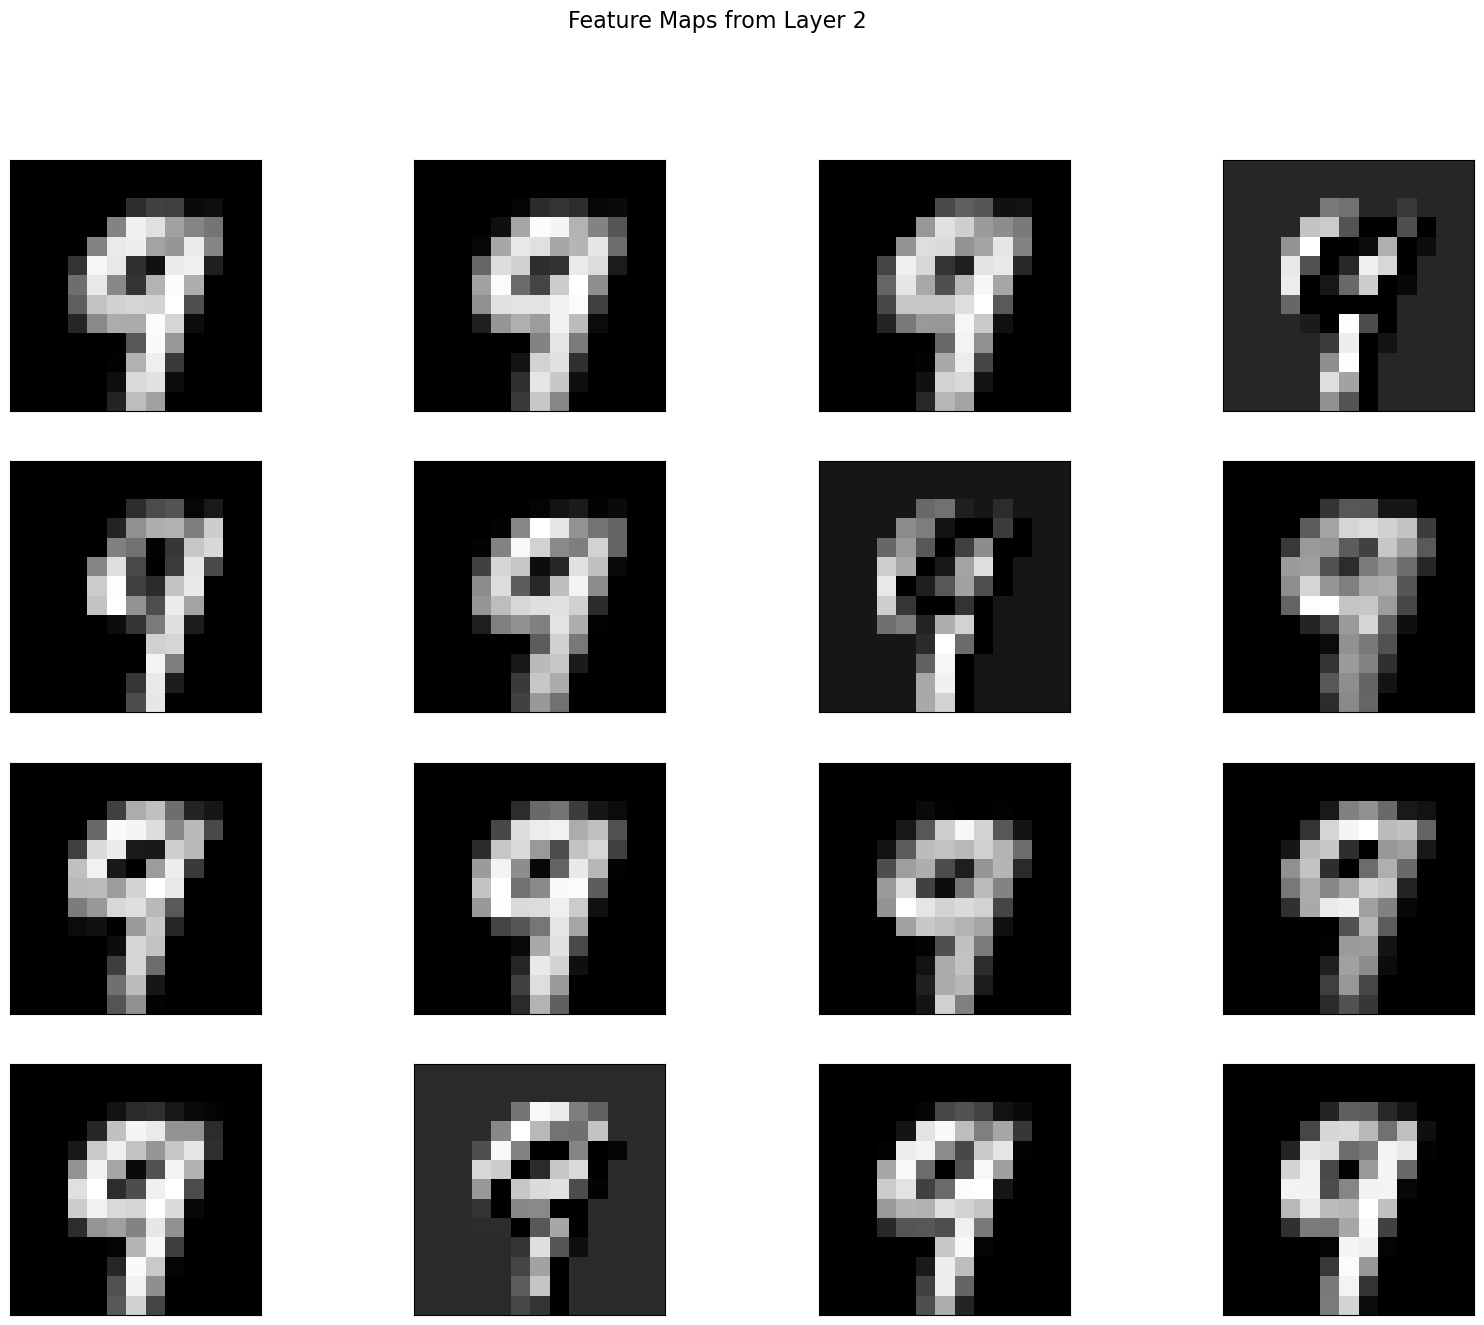

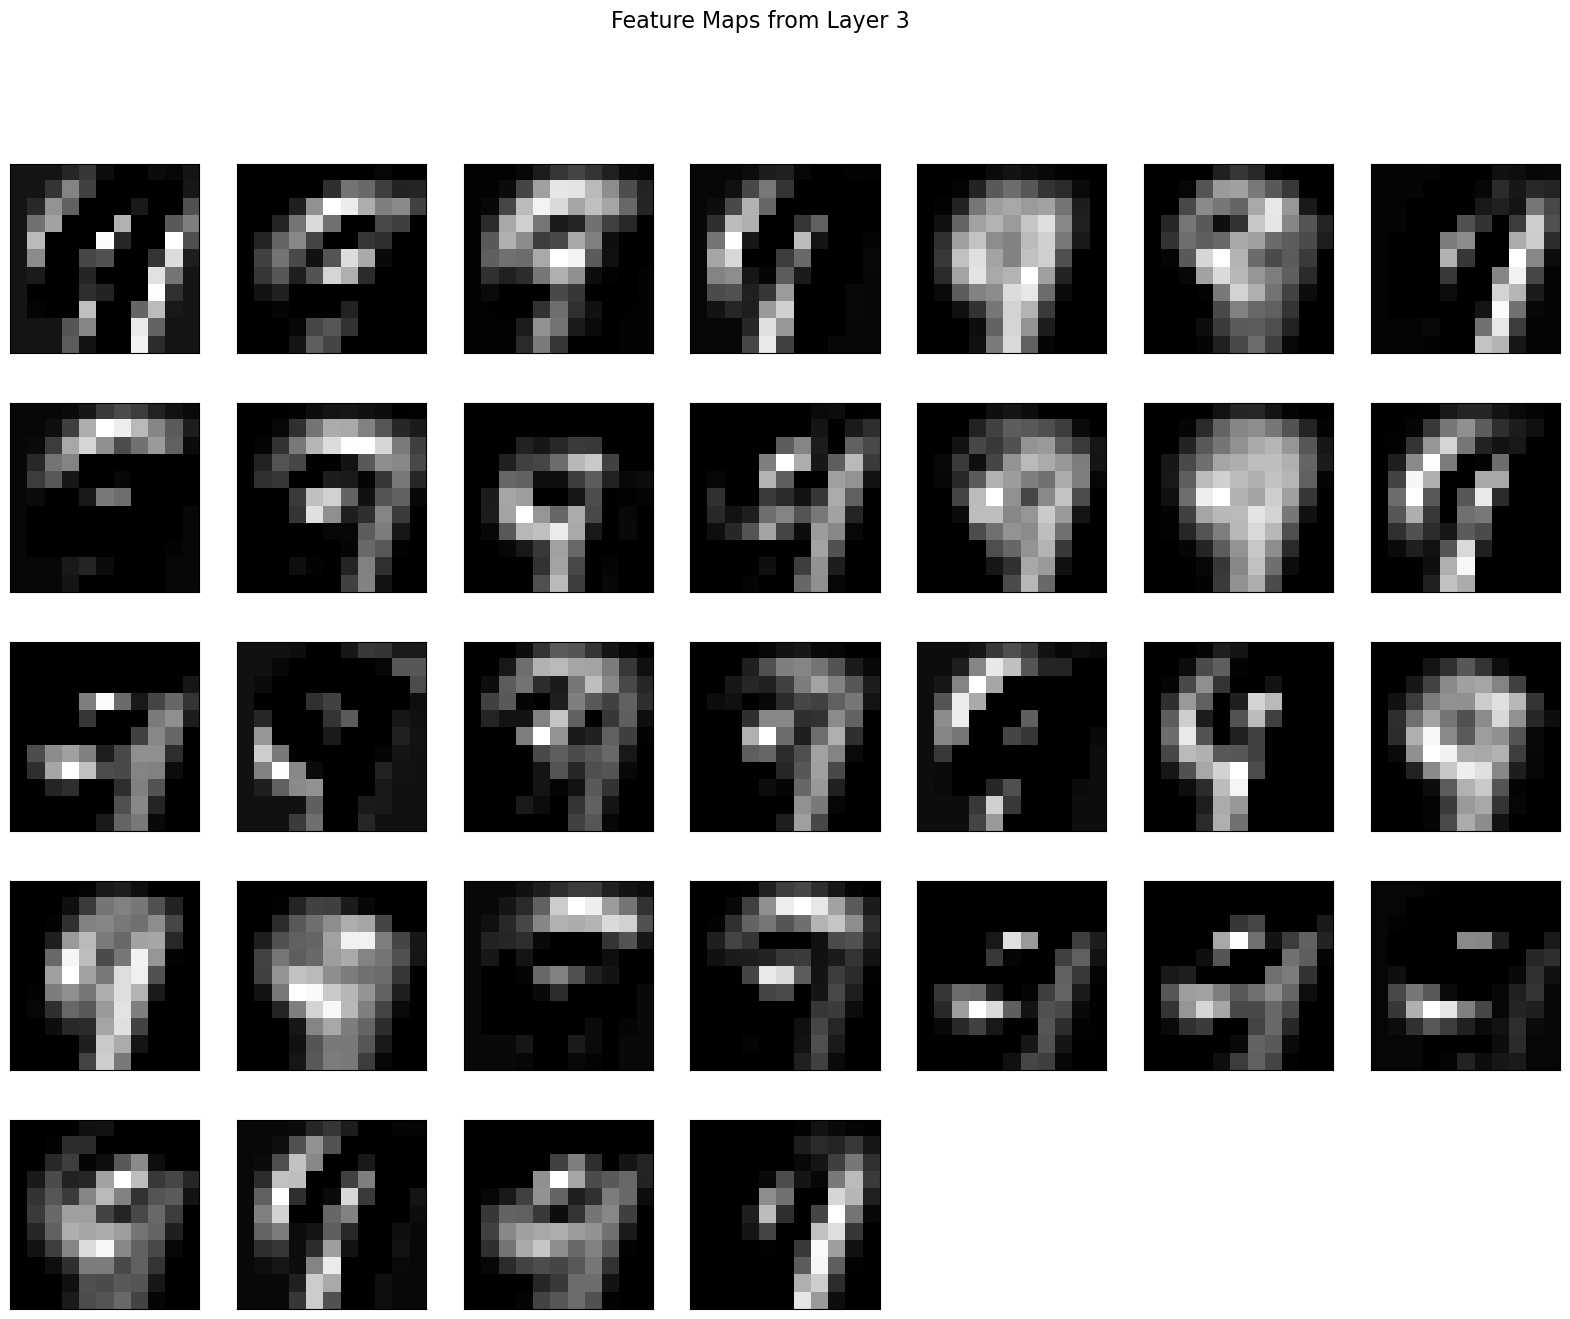

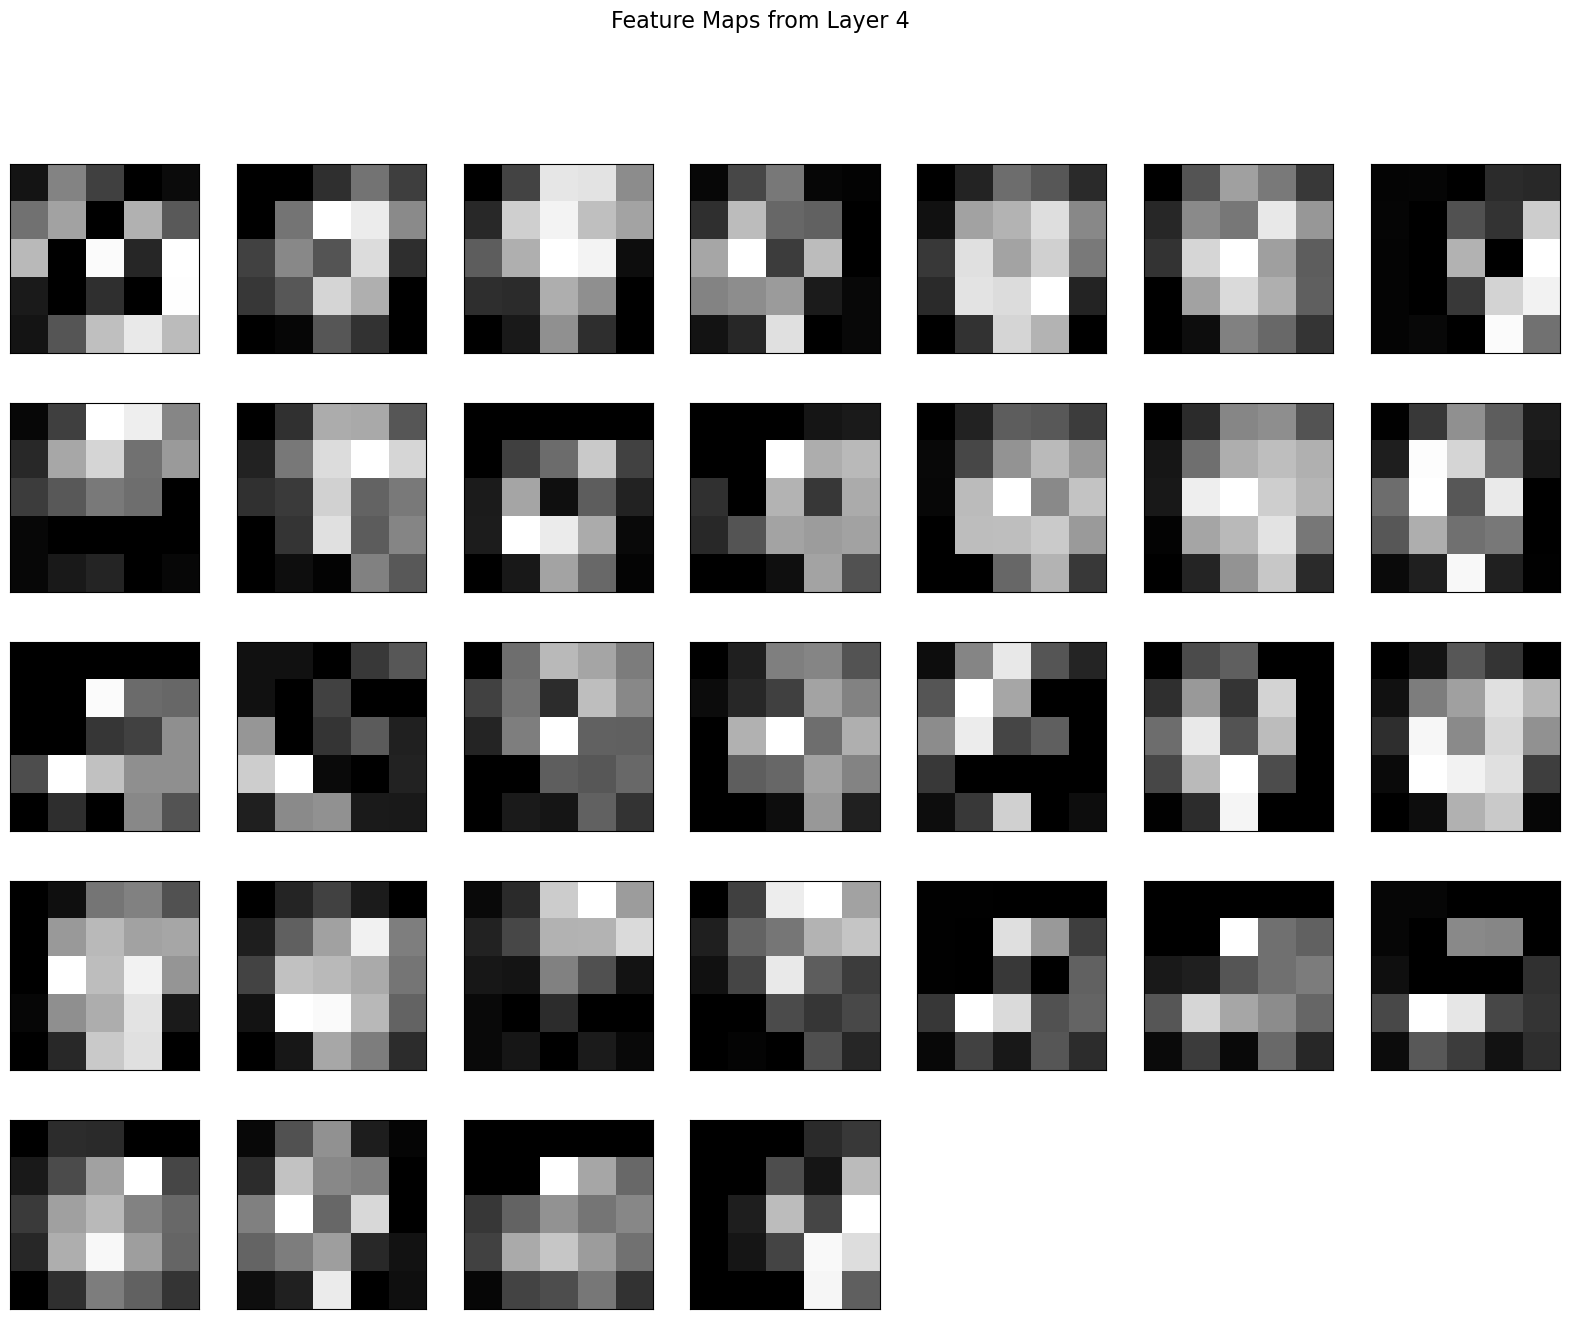

IndexError: too many indices for array: array is 2-dimensional, but 4 were indexed

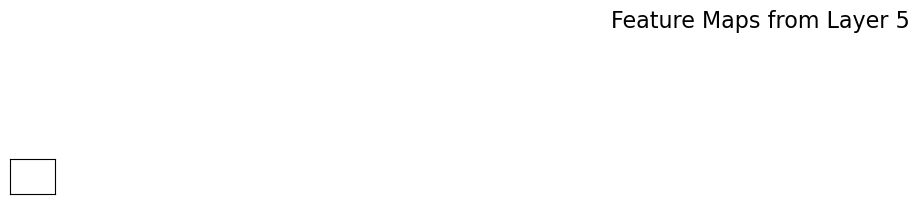

In [194]:
testImageIndexToTry = 12
testImage = np.expand_dims(test_images[testImageIndexToTry], axis=0)

# Get feature maps for the test image
feature_maps = model_shortened.predict(testImage)

# Visualize the feature maps from each convolutional layer
for layer_index, feature_map in enumerate(feature_maps):
    num_filters = feature_map.shape[-1]
    
    # Dynamically determine the number of rows and columns for the subplots
    rows = int(np.sqrt(num_filters))  # Number of rows
    columns = int(np.ceil(num_filters / rows))  # Number of columns
    
    fig = plt.figure(figsize=(20, 15))
    fig.suptitle(f'Feature Maps from Layer {layer_index + 1}', fontsize=16)

    for i in range(1, num_filters + 1):
        plt.subplot(rows, columns, i)
        plt.xticks([])  # remove x-axis ticks
        plt.yticks([])  # remove y-axis ticks
        plt.imshow(feature_map[0, :, :, i - 1], cmap='gray')
    plt.show()
